[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jseborga/recursos-ia/blob/main/notebooks/04_metodos_numericos.ipynb)

# Métodos numéricos para el plan de estudios de Física

Seis ejemplos ligados a materias del **plan de estudios 2009 de la Carrera de Física (UMSA)**. Cada uno compara el método numérico con una solución exacta y se detiene con `✘` si no coincide.

| # | Ejemplo | Materias del plan 2009 | Control |
|---|---|---|---|
| 1 | Elementos finitos (FEM) en 1D | FIS-243 Cálculo Numérico y Programación · MAT-132 Ecuaciones Diferenciales | Convergencia O(h²) y nodos exactos |
| 2 | Potencial electrostático (Laplace 2D) | FIS-253 Electromagnetismo · FIS-252 Métodos Matemáticos III | Serie de Fourier y simetría: V(centro) = V₀/4 |
| 3 | Series de Fourier y fenómeno de Gibbs | FIS-132 / FIS-242 Métodos Matemáticos I y II | Sobrepaso límite (2/π)·Si(π) |
| 4 | Cuerda vibrante (ecuación de onda) | MAT-132 · FIS-252 | Solución de d'Alembert; criterio de Courant |
| 5 | Pozo de potencial finito | FIS-360 Física Moderna II · FIS-380 Mecánica Cuántica | Dos métodos independientes coinciden |
| 6 | Modelo de Ising 2D (Monte Carlo) | FIS-370 Mecánica Estadística | Solución exacta de Onsager |

*Entorno de ejecución → Ejecutar todo* tarda menos de un minuto en el plan gratuito.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded, eigh_tridiagonal
from scipy.sparse import diags, kron, identity, csr_matrix
from scipy.sparse.linalg import spsolve
from scipy.optimize import brentq
from scipy.special import sici

plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": .3})

def verificar(condicion, mensaje):
    if not condicion:
        raise AssertionError("✘ " + mensaje)
    print("✔", mensaje)

## 1 · Elementos finitos en una dimensión

Problema modelo (barra con carga distribuida, o potencial con densidad de carga):

$$-u''(x) = f(x),\quad 0<x<1,\qquad u(0)=u(1)=0$$

**Formulación débil:** $\int_0^1 u'v'\,dx = \int_0^1 f v\,dx$ para toda función de prueba $v$. Con funciones «sombrero» lineales sobre $N$ elementos de tamaño $h$, queda un sistema tridiagonal $K\mathbf u = \mathbf b$ con $K = \tfrac1h\,\mathrm{tridiag}(-1,2,-1)$.

Prueba: $f = \pi^2\sin\pi x$, cuya solución exacta es $u = \sin\pi x$.

✔ error L² ∝ h^1.997: convergencia de segundo orden, como predice la teoría
✔ en los nodos el error es casi nulo (1.4e-10): superconvergencia nodal en 1D


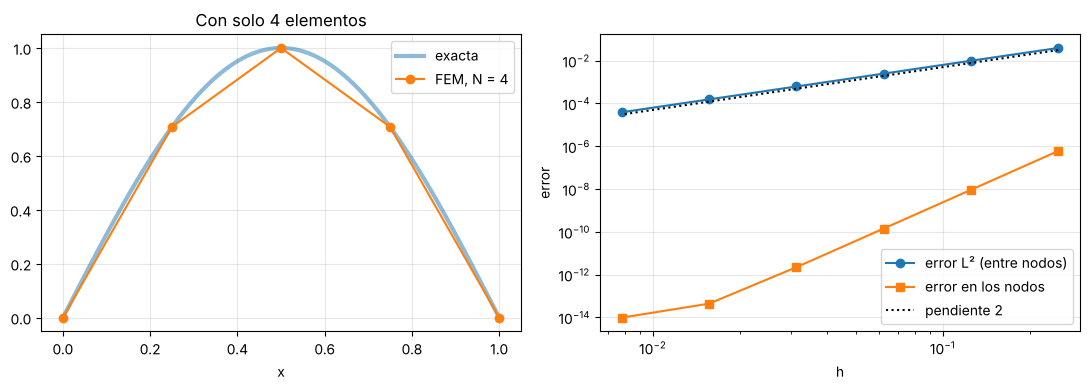

In [2]:
def fem_1d(N, f):
    """Elementos lineales; la carga se integra con cuadratura de Gauss de 3 puntos."""
    x = np.linspace(0, 1, N + 1); h = 1 / N
    K = np.zeros((3, N - 1)); K[0, 1:] = -1 / h; K[1, :] = 2 / h; K[2, :-1] = -1 / h   # forma de bandas
    gp, gw = np.array([-np.sqrt(3/5), 0, np.sqrt(3/5)]), np.array([5/9, 8/9, 5/9])
    b = np.zeros(N + 1)
    for e in range(N):
        xa, xb = x[e], x[e + 1]; xs = (xa + xb)/2 + (xb - xa)/2*gp; w = gw*(xb - xa)/2
        b[e] += np.sum(w*f(xs)*(xb - xs)/h); b[e + 1] += np.sum(w*f(xs)*(xs - xa)/h)
    u = np.zeros(N + 1); u[1:-1] = solve_banded((1, 1), K, b[1:-1])
    return x, u

f = lambda s: np.pi**2*np.sin(np.pi*s); exacta = lambda s: np.sin(np.pi*s)
xf = np.linspace(0, 1, 20001)                     # malla fina para medir el error ENTRE nodos
Ns, eL2, enod = [4, 8, 16, 32, 64, 128], [], []
for N in Ns:
    x, u = fem_1d(N, f)
    uh = np.interp(xf, x, u)                      # la solución FEM es lineal a trozos
    eL2.append(np.sqrt(np.trapezoid((uh - exacta(xf))**2, xf)) if hasattr(np, "trapezoid") else np.sqrt(np.trapz((uh - exacta(xf))**2, xf)))
    enod.append(np.max(np.abs(u - exacta(x))))
orden = np.polyfit(np.log(Ns), np.log(eL2), 1)[0]
verificar(abs(orden + 2) < 0.05, f"error L² ∝ h^{-orden:.3f}: convergencia de segundo orden, como predice la teoría")
verificar(max(enod[2:]) < 1e-9, f"en los nodos el error es casi nulo ({max(enod[2:]):.1e}): superconvergencia nodal en 1D")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
x, u = fem_1d(4, f)
a1.plot(xf, exacta(xf), lw=3, alpha=.5, label="exacta"); a1.plot(x, u, "o-", label="FEM, N = 4")
a1.set_title("Con solo 4 elementos"); a1.set_xlabel("x"); a1.legend()
a2.loglog(1/np.array(Ns), eL2, "o-", label="error L² (entre nodos)")
a2.loglog(1/np.array(Ns), enod, "s-", label="error en los nodos")
a2.loglog(1/np.array(Ns), 0.5*(1/np.array(Ns))**2, "k:", label="pendiente 2")
a2.set_xlabel("h"); a2.set_ylabel("error"); a2.legend(); plt.tight_layout(); plt.show()

**Para el aula:** ¿por qué los valores en los nodos son prácticamente exactos y, sin embargo, el método es «solo» de segundo orden? (En 1D, la función de Green del problema es lineal a trozos con quiebre en el nodo, así que pertenece al espacio de elementos finitos.) Un control que mida solo en los nodos daría una convergencia engañosa.

**Prompt para variar con IA:** «Extiende `fem_1d` a una barra con conductividad variable k(x) = 1 + x y verifica la convergencia contra la solución exacta que obtengas por integración directa.»

## 2 · Potencial electrostático en una caja (ecuación de Laplace 2D)

Caja cuadrada con tres lados a 0 V y el lado superior a $V_0$. Solución exacta por separación de variables:

$$V(x,y) = \sum_{n\ \text{impar}} \frac{4V_0}{n\pi}\,\sin(n\pi x)\,\frac{\sinh(n\pi y)}{\sinh(n\pi)}$$

Numérico: diferencias finitas de 5 puntos y una matriz dispersa. **Control extra:** por superposición de los cuatro lados, en el centro de la caja $V = V_0/4$ exactamente.

✔ V(centro) = 0.250000000000 = V0/4 (superposición de los cuatro lados)
✔ diferencias finitas = serie de Fourier (error máx. 5.6e-04 lejos de las esquinas singulares)


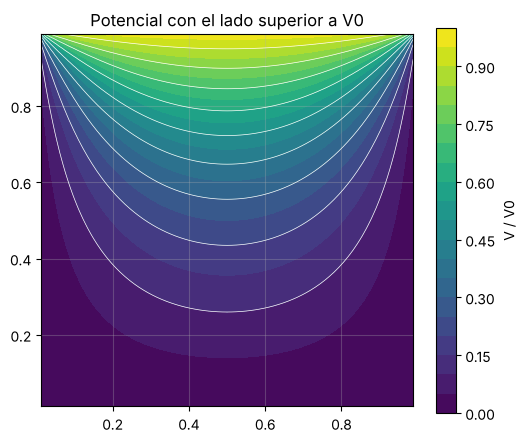

In [3]:
def laplace_caja(n, V0=1.0):
    h = 1/(n + 1)
    T = diags([-1.0, 2.0, -1.0], [-1, 0, 1], shape=(n, n))
    A = (kron(identity(n), T) + kron(T, identity(n)))/h**2
    b = np.zeros((n, n)); b[-1, :] = V0/h**2          # fila superior toca el borde a V0
    V = spsolve(csr_matrix(A), b.ravel()).reshape(n, n)
    xs = np.linspace(h, 1 - h, n)
    return xs, V

def serie(X, Y, terminos=400):
    # sinh(kπy)/sinh(kπ) escrito en forma estable: sinh(kπ) desborda el punto flotante para k > ~225
    V = np.zeros_like(X)
    for k in range(1, terminos, 2):
        cociente = np.exp(k*np.pi*(Y - 1))*(1 - np.exp(-2*k*np.pi*Y))/(1 - np.exp(-2*k*np.pi))
        V += 4/(k*np.pi)*np.sin(k*np.pi*X)*cociente
    return V
xs, V = laplace_caja(81)
X, Y = np.meshgrid(xs, xs)
verificar(abs(V[40, 40] - 0.25) < 1e-10, f"V(centro) = {V[40, 40]:.12f} = V0/4 (superposición de los cuatro lados)")
err = np.max(np.abs(V - serie(X, Y))[Y < 0.9])
verificar(err < 1e-3, f"diferencias finitas = serie de Fourier (error máx. {err:.1e} lejos de las esquinas singulares)")

fig, ax = plt.subplots(figsize=(6, 5))
cs = ax.contourf(X, Y, V, levels=20, cmap="viridis"); ax.contour(X, Y, V, levels=10, colors="w", linewidths=.5)
plt.colorbar(cs, label="V / V0"); ax.set_aspect("equal"); ax.set_title("Potencial con el lado superior a V0"); plt.show()

**Nota de verificación:** la primera versión de este control falló, y no por el método numérico. La serie «exacta» calculaba sinh(nπ), que desborda el punto flotante para n > 225 y produce valores inválidos (NaN). Hasta la solución de referencia hay que verificarla.

**Para el aula:** ¿por qué el error es mayor cerca de las esquinas superiores? (Allí el potencial salta de 0 a V₀: la solución no es suave y la serie converge lentamente.)

**Prompt para variar con IA:** «Calcula el campo eléctrico E = −∇V con `np.gradient`, dibújalo con `streamplot` y verifica numéricamente la ley de Gauss en una superficie interior sin carga.»

## 3 · Series de Fourier y el fenómeno de Gibbs

Onda cuadrada de amplitud 1: $\;s_N(x) = \frac4\pi\sum_{k\ \text{impar}\le N}\frac{\sin kx}{k}$.

Cerca del salto, la suma parcial **siempre** se pasa del valor 1, por muchos términos que se sumen. El máximo tiende a $\frac2\pi\,\mathrm{Si}(\pi) \approx 1{,}17898$: un sobrepaso de casi 9 % del salto.

N =  11: máximo de la suma parcial = 1.181302
N =  51: máximo de la suma parcial = 1.179103


N = 201: máximo de la suma parcial = 1.178988
N = 801: máximo de la suma parcial = 1.178980
✔ el sobrepaso tiende a (2/π)·Si(π) = 1.178980, no a 1


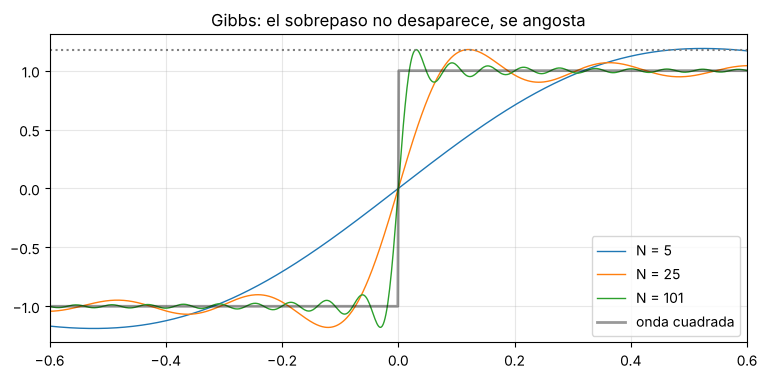

In [4]:
x = np.linspace(1e-5, 0.3, 30001)
limite = 2/np.pi*sici(np.pi)[0]
maximos = {}
for N in (11, 51, 201, 801):
    sN = sum(4/np.pi*np.sin(k*x)/k for k in range(1, N + 1, 2))
    maximos[N] = sN.max()
    print(f"N = {N:>3}: máximo de la suma parcial = {sN.max():.6f}")
verificar(abs(maximos[801] - limite) < 2e-5, f"el sobrepaso tiende a (2/π)·Si(π) = {limite:.6f}, no a 1")

xx = np.linspace(-np.pi, np.pi, 4000)
for N in (5, 25, 101):
    plt.plot(xx, sum(4/np.pi*np.sin(k*xx)/k for k in range(1, N + 1, 2)), lw=1, label=f"N = {N}")
plt.plot(xx, np.sign(xx), "k", lw=2, alpha=.4, label="onda cuadrada")
plt.axhline(limite, ls=":", color="gray"); plt.xlim(-0.6, 0.6); plt.legend(); plt.title("Gibbs: el sobrepaso no desaparece, se angosta"); plt.show()

**Para el aula:** si el sobrepaso no desaparece, ¿en qué sentido la serie «converge» a la onda cuadrada? (Converge punto a punto y en media cuadrática, pero no uniformemente.)

**Prompt para variar con IA:** «Aplica el factor de suavizado de Lanczos (sinc) a la suma parcial y muestra que el sobrepaso desaparece.»

## 4 · Cuerda vibrante: ecuación de onda y número de Courant

$$u_{tt} = c^2 u_{xx},\quad u(0,t)=u(1,t)=0,\quad u(x,0)=\text{cuerda pulsada},\ u_t(x,0)=0$$

Solución exacta de d'Alembert con la extensión impar y periódica del perfil inicial. Esquema explícito centrado con número de Courant $C = c\,\Delta t/\Delta x$:

- $C = 1$: el esquema es **exacto** en los nodos (curiosidad notable).
- $C < 1$: error pequeño por dispersión numérica.
- $C > 1$: inestable (criterio CFL), igual que la ecuación del calor con $r > ½$.

C = 1.0 : error máximo = 8.67e-17
C = 0.5 : error máximo = 1.42e-03
C = 1.02: error máximo = 2.21e+18
✔ con C = 1 el esquema reproduce exactamente a d'Alembert
✔ con C = 0,5 el error es pequeño (dispersión numérica)
✔ con C = 1,02 el esquema explota: criterio de Courant violado


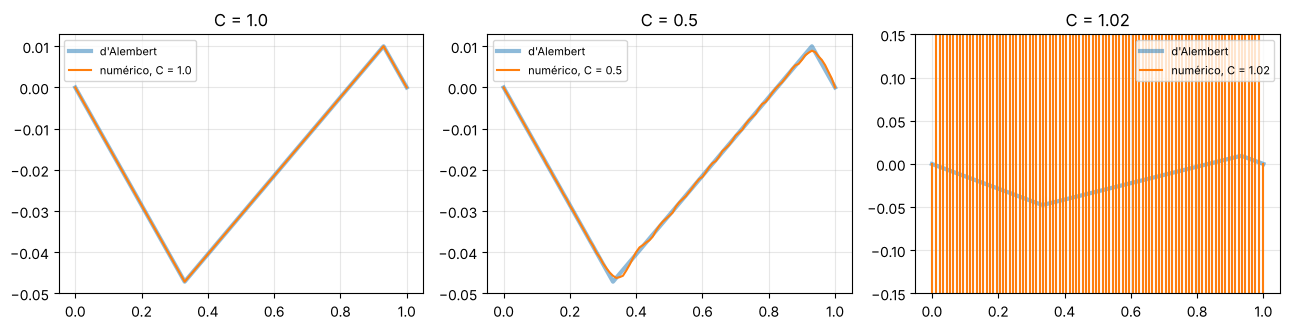

In [5]:
def pulsada(s):                       # perfil triangular: se pulsa en x = 0,3 con altura 0,1
    return np.where(s < 0.3, s/0.3*0.1, 0.1*(1 - s)/0.7)
def extension(s):                     # extensión impar y periódica (período 2)
    s = np.mod(s, 2.0); return np.where(s <= 1, pulsada(s), -pulsada(2 - s))

def cuerda(C, Nx=100, t_fin=1.37):
    x = np.linspace(0, 1, Nx + 1); dt = C*(x[1] - x[0]); n = int(round(t_fin/dt))
    u0 = pulsada(x); u1 = u0.copy()
    u1[1:-1] = u0[1:-1] + 0.5*C**2*(u0[2:] - 2*u0[1:-1] + u0[:-2])
    for _ in range(1, n):
        u2 = np.zeros_like(u0); u2[1:-1] = 2*u1[1:-1] - u0[1:-1] + C**2*(u1[2:] - 2*u1[1:-1] + u1[:-2]); u0, u1 = u1, u2
    t = n*dt
    return x, u1, 0.5*(extension(x - t) + extension(x + t))

res = {}
for C in (1.0, 0.5, 1.02):
    x, u, ex = cuerda(C); res[C] = (x, u, ex); e = np.max(np.abs(u - ex))
    print(f"C = {C:<4}: error máximo = {e:.2e}")
verificar(np.max(np.abs(res[1.0][1] - res[1.0][2])) < 1e-12, "con C = 1 el esquema reproduce exactamente a d'Alembert")
verificar(np.max(np.abs(res[0.5][1] - res[0.5][2])) < 5e-3, "con C = 0,5 el error es pequeño (dispersión numérica)")
verificar(np.max(np.abs(res[1.02][1])) > 1, "con C = 1,02 el esquema explota: criterio de Courant violado")

fig, axs = plt.subplots(1, 3, figsize=(13, 3.4), sharey=False)
for ax, C in zip(axs, (1.0, 0.5, 1.02)):
    x, u, ex = res[C]; ax.plot(x, ex, lw=3, alpha=.5, label="d'Alembert"); ax.plot(x, u, label=f"numérico, C = {C}")
    ax.set_title(f"C = {C}"); ax.legend(fontsize=8)
axs[2].set_ylim(-0.15, 0.15); plt.tight_layout(); plt.show()

**Para el aula:** ¿por qué C = 1 da la solución exacta? (Con Δx = cΔt, la información viaja exactamente un nodo por paso, igual que las características de la ecuación.)

**Prompt para variar con IA:** «Agrega amortiguamiento (término −γ u_t) y compara la energía de la cuerda con la predicción E(t) = E₀ e^(−γt).»

## 5 · Pozo de potencial finito: dos métodos independientes

Unidades $\hbar = m = 1$; pozo de profundidad $V_0 = 10$ y semiancho $a = 1$.

- **Método A (analítico + raíces):** los estados pares cumplen $k\tan(ka) = \kappa$ y los impares $-k\cot(ka) = \kappa$, con $k = \sqrt{2(E+V_0)}$ y $\kappa = \sqrt{-2E}$. Se resuelven con `brentq`.
- **Método B (matricial):** diferencias finitas del hamiltoniano y autovalores de una matriz tridiagonal.

Si dos métodos sin nada en común dan las mismas energías, la confianza en ambos sube mucho.

Estados ligados previstos: 3  (z0 = a√(2V0) = 4.472)
  n = 0: raíces E = -9.18026   matriz E = -9.18049   diferencia relativa = 2.6e-05
  n = 1: raíces E = -6.77906   matriz E = -6.77996   diferencia relativa = 1.3e-04
  n = 2: raíces E = -3.05423   matriz E = -3.05602   diferencia relativa = 5.9e-04
✔ los dos métodos encuentran el mismo número de estados ligados
✔ las energías coinciden mejor que 0,1 %


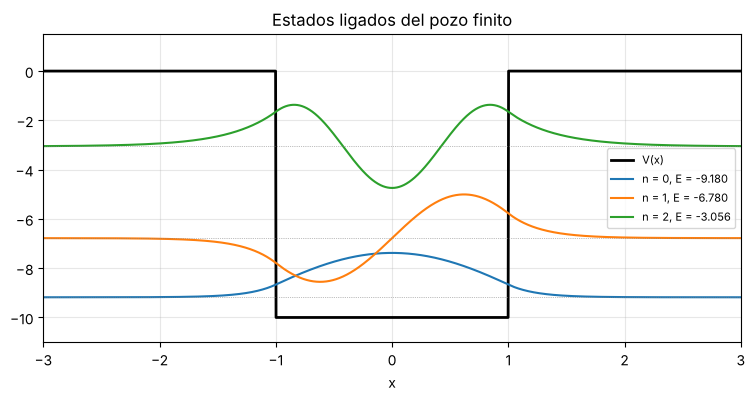

In [6]:
V0, a = 10.0, 1.0
def par(E):   k, q = np.sqrt(2*(E + V0)), np.sqrt(-2*E); return k*np.sin(k*a) - q*np.cos(k*a)
def impar(E): k, q = np.sqrt(2*(E + V0)), np.sqrt(-2*E); return k*np.cos(k*a) + q*np.sin(k*a)
Es = np.linspace(-V0 + 1e-9, -1e-9, 200001); raices = []
for fn in (par, impar):
    v = fn(Es); idx = np.where(np.sign(v[:-1]) != np.sign(v[1:]))[0]
    raices += [brentq(fn, Es[i], Es[i + 1]) for i in idx]
raices = np.sort(raices)

L, N = 12.0, 6000
x = np.linspace(-L, L, N); h = x[1] - x[0]; Vx = np.where(np.abs(x) < a, -V0, 0.0)
E_fd, psi = eigh_tridiagonal(1/h**2 + Vx, -0.5/h**2*np.ones(N - 1), select="v", select_range=(-V0, 0))

z0 = a*np.sqrt(2*V0)
print(f"Estados ligados previstos: {int(np.ceil(2*z0/np.pi))}  (z0 = a√(2V0) = {z0:.3f})")
for n, (ea, eb) in enumerate(zip(raices, E_fd)):
    print(f"  n = {n}: raíces E = {ea:.5f}   matriz E = {eb:.5f}   diferencia relativa = {abs(ea - eb)/abs(ea):.1e}")
verificar(len(raices) == len(E_fd) == int(np.ceil(2*z0/np.pi)), "los dos métodos encuentran el mismo número de estados ligados")
verificar(np.max(np.abs(raices - E_fd)/np.abs(raices)) < 1e-3, "las energías coinciden mejor que 0,1 %")

plt.plot(x, Vx, "k", lw=2, label="V(x)")
for n in range(len(E_fd)):
    p = psi[:, n]/np.sqrt(h); plt.plot(x, E_fd[n] + 2*p, label=f"n = {n}, E = {E_fd[n]:.3f}"); plt.axhline(E_fd[n], color="gray", lw=.5, ls=":")
plt.xlim(-3, 3); plt.ylim(-11, 1.5); plt.xlabel("x"); plt.legend(fontsize=8); plt.title("Estados ligados del pozo finito"); plt.show()

**Para el aula:** la función de onda «se mete» en la región prohibida |x| > a. ¿Cuánto penetra, y cómo depende de E? (Longitud de penetración 1/κ.)

**Prompt para variar con IA:** «Calcula la probabilidad de encontrar la partícula fuera del pozo para cada estado y explica por qué crece con n.»

## 6 · Modelo de Ising 2D: Monte Carlo frente a la solución exacta de Onsager

Red de 32 × 32 espines con algoritmo de Metropolis (actualización en tablero de ajedrez, vectorizada). Lars Onsager resolvió exactamente este modelo en 1944: por debajo de $T_c = 2/\ln(1+\sqrt2) \approx 2{,}269$ (unidades $J = k_B = 1$), la magnetización espontánea es

$$M(T) = \left[1 - \sinh^{-4}(2/T)\right]^{1/8}$$

Por encima de $T_c$, $M = 0$ en una red infinita; en una red finita queda un valor pequeño (efecto de tamaño finito).

✔ T = 1.8: Monte Carlo M = 0.9577 frente a Onsager 0.9569 (diferencia < 2 %)
✔ T = 2.0: Monte Carlo M = 0.9123 frente a Onsager 0.9113 (diferencia < 2 %)


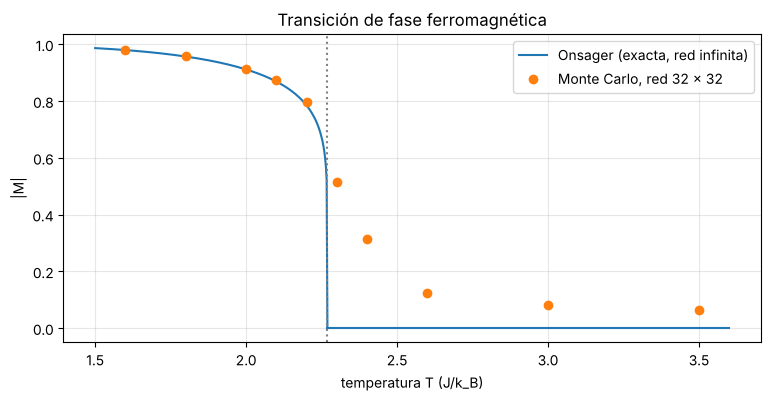

In [7]:
def ising(T, L=32, barridos=1500, termalizacion=500, semilla=2026):
    rng = np.random.default_rng(semilla); s = np.ones((L, L), dtype=int); i, j = np.indices((L, L)); m = []
    for b in range(barridos):
        for paridad in (0, 1):
            mascara = (i + j) % 2 == paridad
            vecinos = np.roll(s, 1, 0) + np.roll(s, -1, 0) + np.roll(s, 1, 1) + np.roll(s, -1, 1)
            acepta = (rng.random((L, L)) < np.exp(-2*s*vecinos/T)) & mascara
            s[acepta] *= -1
        if b >= termalizacion: m.append(abs(s.mean()))
    return np.mean(m)

Tc = 2/np.log(1 + np.sqrt(2))
onsager = lambda T: (1 - np.sinh(2/T)**-4)**0.125 if T < Tc else 0.0
Ts = np.array([1.6, 1.8, 2.0, 2.1, 2.2, 2.3, 2.4, 2.6, 3.0, 3.5])
M = np.array([ising(T) for T in Ts])
for T in (1.8, 2.0):
    mc, ex = M[Ts == T][0], onsager(T)
    verificar(abs(mc - ex)/ex < 0.02, f"T = {T}: Monte Carlo M = {mc:.4f} frente a Onsager {ex:.4f} (diferencia < 2 %)")

Tf = np.linspace(1.5, Tc, 300)
plt.plot(Tf, [onsager(T) for T in Tf], label="Onsager (exacta, red infinita)"); plt.plot([Tc, 3.6], [0, 0], color="C0")
plt.plot(Ts, M, "o", label="Monte Carlo, red 32 × 32"); plt.axvline(Tc, ls=":", color="gray")
plt.xlabel("temperatura T (J/k_B)"); plt.ylabel("|M|"); plt.legend(); plt.title("Transición de fase ferromagnética"); plt.show()

**Para el aula:** ¿por qué la simulación no da M = 0 exactamente por encima de T_c? Prueben con L = 16 y L = 64 y observen cómo cambia la «cola».

**Prompt para variar con IA:** «Agrega el cálculo de la susceptibilidad χ = L²(⟨M²⟩ − ⟨|M|⟩²)/T y ubica su máximo; compáralo con T_c.»

---
*Material del Módulo 8, «El auxiliar aumentado». Referencia del plan de estudios: Carrera de Física, UMSA, Plan de Estudios 2009 – Nivel Licenciatura (publicado por la FCPN). Licencia CC BY 4.0.*